# AquaGuard AI — Abnormal Consumption Exploratory Data Analysis (EDA)
**Task:** Exploratory Data Analysis of Smart Meter Water Consumption Time-Series  
**Dataset:** `data/synthetic/abnormal_consumption.csv` (311,040 rows, 12 meters, 6 zones, 90 days at 5-minute sampling)  
**Target:** `is_anomaly` (0 = Normal, 1 = Abnormal)  

---
### Notebook Objectives
1. Perform comprehensive dataset overview, schema inspection, and data quality checks.
2. Analyze missing values, rolling-window baseline artifacts, and timestamp continuity.
3. Evaluate class distribution, anomaly types, and event structures.
4. Explore spatial (zone-wise, meter-wise) and temporal (diurnal hour-wise, day-of-week) consumption patterns.
5. Investigate operational correlations (occupancy, scheduled activities, temperature) against consumption.
6. Contrast normal vs abnormal hydraulic regimes and identify multi-feature interactions.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configure aesthetic style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['font.family'] = 'sans-serif'
os.makedirs('../results/figures', exist_ok=True)
os.makedirs('results/figures', exist_ok=True)

# Load dataset
DATA_PATH = '../data/synthetic/abnormal_consumption.csv' if os.path.exists('../data/synthetic/abnormal_consumption.csv') else 'data/synthetic/abnormal_consumption.csv'
df = pd.read_csv(DATA_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])
print(f"Dataset Loaded Successfully! Shape: {df.shape}")


Dataset Loaded Successfully! Shape: (311040, 20)


## 1. Dataset Overview and Schema Inspection
We inspect data types, memory footprint, and column definitions.


In [2]:
print("Dataset Info:")
df.info()
print("\nFirst 5 Rows:")
display(df.head())


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 311040 entries, 0 to 311039
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   timestamp                    311040 non-null  datetime64[ns]
 1   campus_id                    311040 non-null  object        
 2   zone_id                      311040 non-null  object        
 3   zone_type                    311040 non-null  object        
 4   meter_id                     311040 non-null  object        
 5   hour                         311040 non-null  float64       
 6   day_of_week                  311040 non-null  int64         
 7   is_weekend                   311040 non-null  int64         
 8   is_holiday                   311040 non-null  int64         
 9   occupancy                    311040 non-null  float64       
 10  scheduled_activity           311040 non-null  int64         
 11  temperature_

,timestamp,campus_id,zone_id,zone_type,meter_id,hour,day_of_week,is_weekend,is_holiday,occupancy,scheduled_activity,temperature_c,interval_consumption_liters,previous_1h_avg_liters,previous_24h_avg_liters,previous_1h_std_liters,is_anomaly,anomaly_type,event_id,source
0,2026-07-01 00:00:00,CAMPUS_01,HOSTEL,Hostel,M01,0.000000,2,0,0,0.552090,0,33.981039,0.696694,NaN,NaN,0.000000,0,normal,NaN,synthetic_simulation
1,2026-07-01 00:05:00,CAMPUS_01,HOSTEL,Hostel,M01,0.083333,2,0,0,0.505887,0,32.506175,0.566841,0.696694,0.696694,0.000000,0,normal,NaN,synthetic_simulation
2,2026-07-01 00:10:00,CAMPUS_01,HOSTEL,Hostel,M01,0.166667,2,0,0,0.587032,0,33.367459,0.518475,0.631767,0.631767,0.091820,0,normal,NaN,synthetic_simulation
3,2026-07-01 00:15:00,CAMPUS_01,HOSTEL,Hostel,M01,0.250000,2,0,0,0.646276,0,33.884755,0.662876,0.594003,0.594003,0.092162,0,normal,NaN,synthetic_simulation
4,2026-07-01 00:20:00,CAMPUS_01,HOSTEL,Hostel,M01,0.333333,2,0,0,0.658185,0,33.628216,0.567109,0.611221,0.611221,0.082755,0,normal,NaN,synthetic_simulation


## 2. Missing Values, Invalid Records, and Continuity Analysis
We verify whether missing values exist, examine whether they stem from initial rolling-window calculations, and check continuity.


In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
dq_df = pd.DataFrame({'Missing_Count': missing, 'Percentage': missing_pct})
display(dq_df[dq_df['Missing_Count'] > 0])

duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {duplicates}")

# Timestamp continuity per meter
meters = df['meter_id'].unique()
print(f"Total unique meters: {len(meters)} ({list(meters)})")
for m in meters[:3]:
    sub = df[df['meter_id'] == m].sort_values('timestamp')
    step_diffs = sub['timestamp'].diff().dropna().unique()
    print(f"Meter {m}: record count = {len(sub)}, unique sampling steps = {step_diffs}")


,Missing_Count,Percentage
previous_1h_avg_liters,12,0.003858
previous_24h_avg_liters,12,0.003858
event_id,309512,99.508745


Total duplicate rows: 0
Total unique meters: 12 (['M01', 'M02', 'M03', 'M04', 'M05', 'M06', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12'])
Meter M01: record count = 25920, unique sampling steps = <TimedeltaArray>
['0 days 00:05:00']
Length: 1, dtype: timedelta64[ns]
Meter M02: record count = 25920, unique sampling steps = <TimedeltaArray>
['0 days 00:05:00']
Length: 1, dtype: timedelta64[ns]
Meter M03: record count = 25920, unique sampling steps = <TimedeltaArray>
['0 days 00:05:00']
Length: 1, dtype: timedelta64[ns]


## 3. Target Class and Anomaly Type Distribution
Investigating the severity of class imbalance in `is_anomaly` and the composition of `anomaly_type`.


C:\Users\KANISH K\AppData\Local\Temp\ipykernel_26084\3304955476.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=['#1f77b4', '#d62728'])
C:\Users\KANISH K\AppData\Local\Temp\ipykernel_26084\3304955476.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=type_counts.values, y=type_counts.index, ax=axes[1], palette='flare')


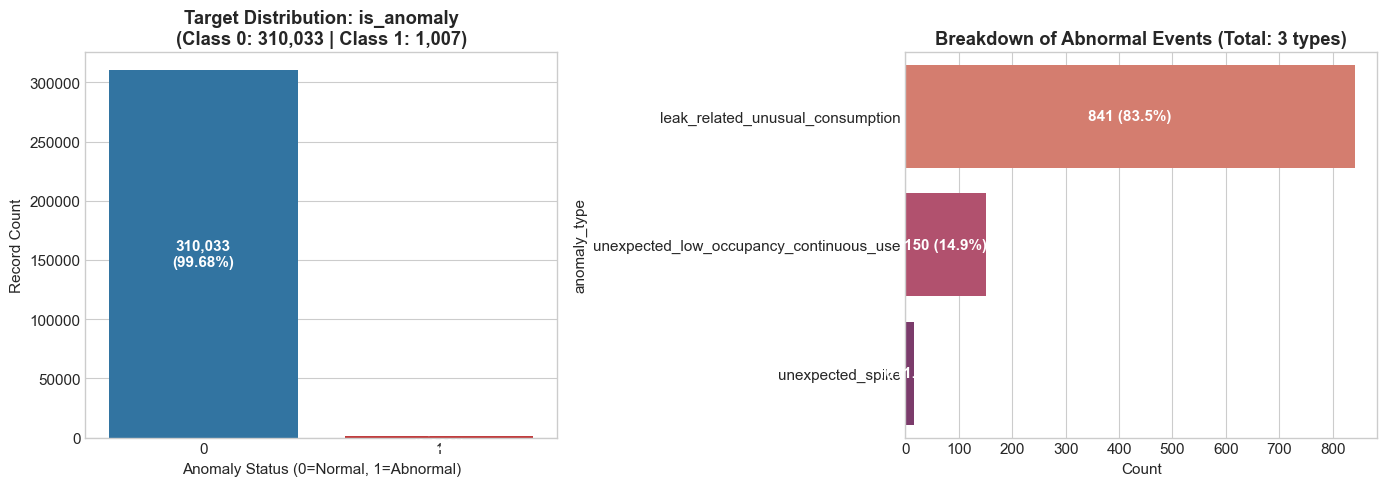

Key Finding: Extreme class imbalance. Only 1,007 records (0.32%) are abnormal, reflecting realistic industrial SCADA operating conditions.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Class distribution
class_counts = df['is_anomaly'].value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, ax=axes[0], palette=['#1f77b4', '#d62728'])
axes[0].set_title(f"Target Distribution: is_anomaly\n(Class 0: {class_counts[0]:,} | Class 1: {class_counts[1]:,})", fontweight='bold')
axes[0].set_xlabel("Anomaly Status (0=Normal, 1=Abnormal)")
axes[0].set_ylabel("Record Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.2f}%)", 
                     (p.get_x() + p.get_width()/2., p.get_height()/2),
                     ha='center', va='center', color='white', fontweight='bold')

# Anomaly type breakdown
type_counts = df[df['is_anomaly'] == 1]['anomaly_type'].value_counts()
sns.barplot(x=type_counts.values, y=type_counts.index, ax=axes[1], palette='flare')
axes[1].set_title(f"Breakdown of Abnormal Events (Total: {len(type_counts.index)} types)", fontweight='bold')
axes[1].set_xlabel("Count")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_width()):,} ({p.get_width()/class_counts[1]*100:.1f}%)", 
                     (p.get_width()/2, p.get_y() + p.get_height()/2.),
                     ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
fig_path = '../results/figures/01_abnormal_class_distribution.png' if os.path.exists('../results') else 'results/figures/01_abnormal_class_distribution.png'
plt.savefig(fig_path, dpi=300)
plt.show()

print("Key Finding: Extreme class imbalance. Only 1,007 records (0.32%) are abnormal, reflecting realistic industrial SCADA operating conditions.")


## 4. Descriptive Statistics: Normal vs Abnormal
We compare hydraulic and environmental parameters between normal operation and abnormal incidents.


In [5]:
features = ['interval_consumption_liters', 'previous_1h_avg_liters', 'previous_24h_avg_liters', 
            'previous_1h_std_liters', 'occupancy', 'temperature_c']
stat_comp = df.groupby('is_anomaly')[features].describe().T
display(stat_comp)


is_anomaly                                     0            1
interval_consumption_liters count  310033.000000  1007.000000
                            mean        0.472078     6.681584
                            std         0.596501     4.349223
                            min         0.030000     0.955582
                            25%         0.030000     4.553598
                            50%         0.184003     6.606265
                            75%         0.676152     7.952622
                            max         4.265350    22.929743
previous_1h_avg_liters      count  310021.000000  1007.000000
                            mean        0.476888     5.204176
                            std         0.604561     3.855949
                            min         0.030000     0.043708
                            25%         0.074399     2.028892
                            50%         0.123601     5.035717
                            75%         0.683753     6.926318
                            max        22.767943    22.763659
previous_24h_avg_liters     count  310021.000000  1007.000000
                            mean        0.489947     0.777197
                            std         0.385130     0.477342
                            min         0.030000     0.059848
                            25%         0.161653     0.344184
                            50%         0.298799     0.715292
                            75%         0.681403     1.182680
                            max         2.151429     2.106793
previous_1h_std_liters      count  310033.000000  1007.000000
                            mean        0.120098     1.102229
                            std         0.178556     1.822500
                            min         0.000000     0.011642
                            25%         0.061425     0.068790
                            50%         0.088346     0.311163
                            75%         0.132749     1.388549
                            max        11.600856    11.657661
occupancy                   count  310033.000000  1007.000000
                            mean        0.358232     0.308075
                            std         0.298963     0.281056
                            min         0.000000     0.000000
                            25%         0.087895     0.076489
                            50%         0.160537     0.139644
                            75%         0.657584     0.627200
                            max         1.000000     0.915864
temperature_c               count  310033.000000  1007.000000
                            mean       31.597270    31.237671
                            std         1.804394     1.620888
                            min        24.761375    27.089475
                            25%        30.289651    30.032910
                            50%        31.581048    31.132787
                            75%        32.986854    32.405233
                            max        36.949640    35.863296

## 5. Spatial Analysis: Zone-wise Water Consumption
Campus zones have distinct hydraulic baselines: Hostels and Canteens experience high peak volumetric throughput, whereas Admin and Library exhibit lower quiescent demand.


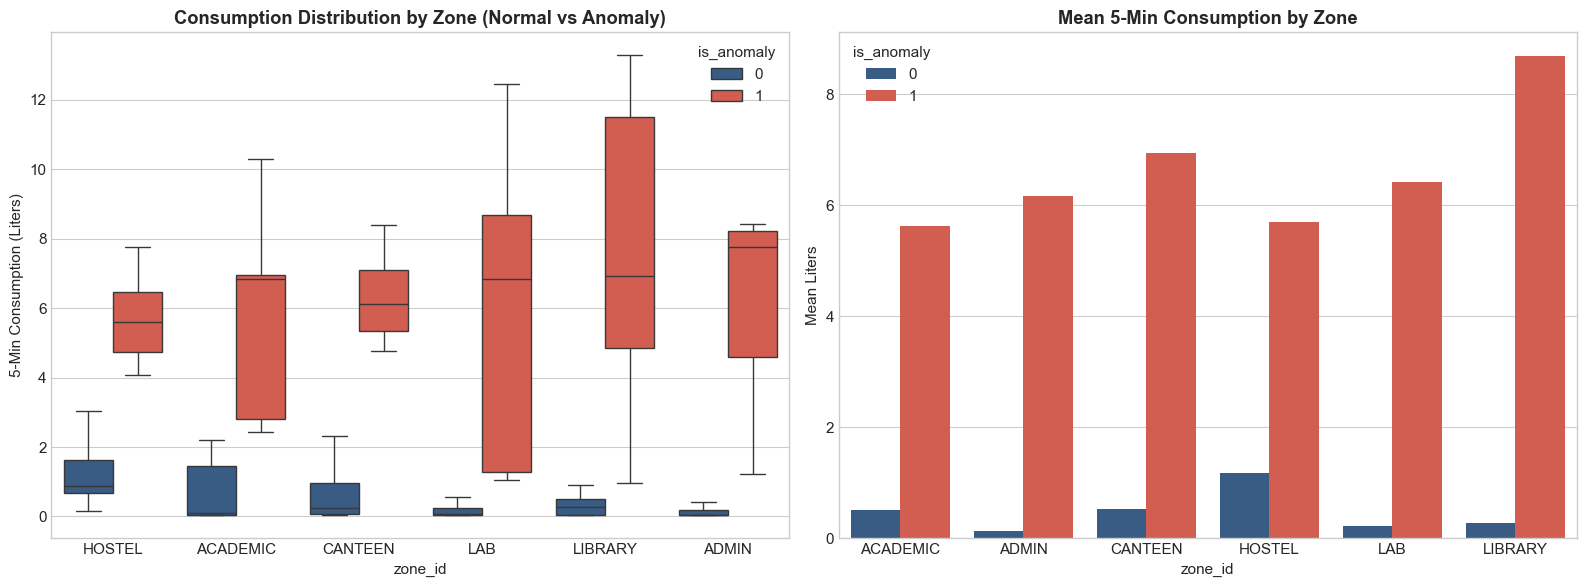

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(x='zone_id', y='interval_consumption_liters', hue='is_anomaly', data=df, ax=axes[0], palette=['#2b5c8f', '#e74c3c'], showfliers=False)
axes[0].set_title("Consumption Distribution by Zone (Normal vs Anomaly)", fontweight='bold')
axes[0].set_ylabel("5-Min Consumption (Liters)")

zone_agg = df.groupby(['zone_id', 'is_anomaly'])['interval_consumption_liters'].agg(['mean', 'median', 'std']).reset_index()
sns.barplot(x='zone_id', y='mean', hue='is_anomaly', data=zone_agg, ax=axes[1], palette=['#2b5c8f', '#e74c3c'])
axes[1].set_title("Mean 5-Min Consumption by Zone", fontweight='bold')
axes[1].set_ylabel("Mean Liters")

plt.tight_layout()
fig_path = '../results/figures/01_zone_consumption.png' if os.path.exists('../results') else 'results/figures/01_zone_consumption.png'
plt.savefig(fig_path, dpi=300)
plt.show()


## 6. Temporal Patterns: Diurnal Profiles and Weekend Effects
Diurnal consumption reflects campus lifestyle. Abnormal consumption deviates significantly from expected circadian baselines, particularly during overnight hours (00:00 - 05:00).


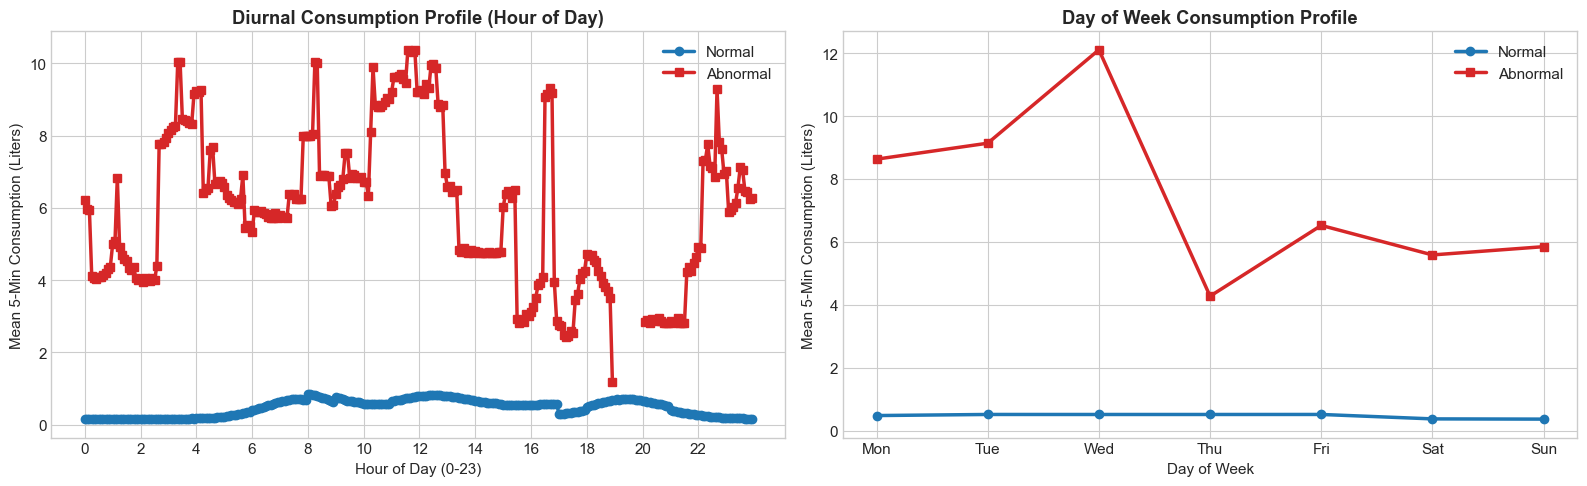

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Diurnal profile
hourly = df.groupby(['hour', 'is_anomaly'])['interval_consumption_liters'].mean().unstack()
axes[0].plot(hourly.index, hourly[0], label='Normal', color='#1f77b4', marker='o', linewidth=2.5)
axes[0].plot(hourly.index, hourly[1], label='Abnormal', color='#d62728', marker='s', linewidth=2.5)
axes[0].set_title("Diurnal Consumption Profile (Hour of Day)", fontweight='bold')
axes[0].set_xlabel("Hour of Day (0-23)")
axes[0].set_ylabel("Mean 5-Min Consumption (Liters)")
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()

# Day of week profile
dow = df.groupby(['day_of_week', 'is_anomaly'])['interval_consumption_liters'].mean().unstack()
dow_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
axes[1].plot(dow_names, dow[0], label='Normal', color='#1f77b4', marker='o', linewidth=2.5)
axes[1].plot(dow_names, dow[1], label='Abnormal', color='#d62728', marker='s', linewidth=2.5)
axes[1].set_title("Day of Week Consumption Profile", fontweight='bold')
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Mean 5-Min Consumption (Liters)")
axes[1].legend()

plt.tight_layout()
fig_path = '../results/figures/01_temporal_profiles.png' if os.path.exists('../results') else 'results/figures/01_temporal_profiles.png'
plt.savefig(fig_path, dpi=300)
plt.show()


## 7. Contextual Interactions: Occupancy & Scheduled Activity
Normal consumption exhibits strong positive coupling with building occupancy and scheduled events. Anomalies frequently manifest as high consumption during zero-occupancy periods (e.g. overnight burst).


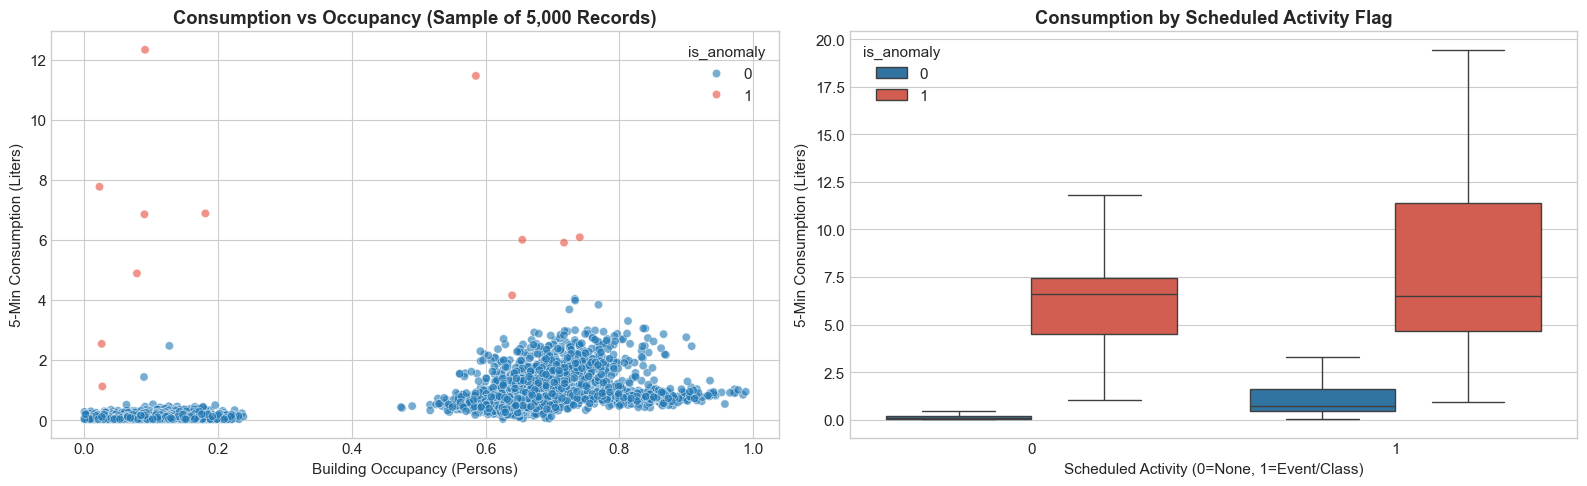

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter with opacity
sns.scatterplot(x='occupancy', y='interval_consumption_liters', hue='is_anomaly', 
                data=df.sample(5000, random_state=42), alpha=0.6, palette=['#1f77b4', '#e74c3c'], ax=axes[0])
axes[0].set_title("Consumption vs Occupancy (Sample of 5,000 Records)", fontweight='bold')
axes[0].set_xlabel("Building Occupancy (Persons)")
axes[0].set_ylabel("5-Min Consumption (Liters)")

# Scheduled activity
sns.boxplot(x='scheduled_activity', y='interval_consumption_liters', hue='is_anomaly', 
            data=df, ax=axes[1], palette=['#1f77b4', '#e74c3c'], showfliers=False)
axes[1].set_title("Consumption by Scheduled Activity Flag", fontweight='bold')
axes[1].set_xlabel("Scheduled Activity (0=None, 1=Event/Class)")
axes[1].set_ylabel("5-Min Consumption (Liters)")

plt.tight_layout()
fig_path = '../results/figures/01_occupancy_interaction.png' if os.path.exists('../results') else 'results/figures/01_occupancy_interaction.png'
plt.savefig(fig_path, dpi=300)
plt.show()


## 8. Rolling Baseline and Variance Drift Analysis
Examining historical baseline tracking: `previous_1h_avg_liters`, `previous_24h_avg_liters`, and `previous_1h_std_liters`.


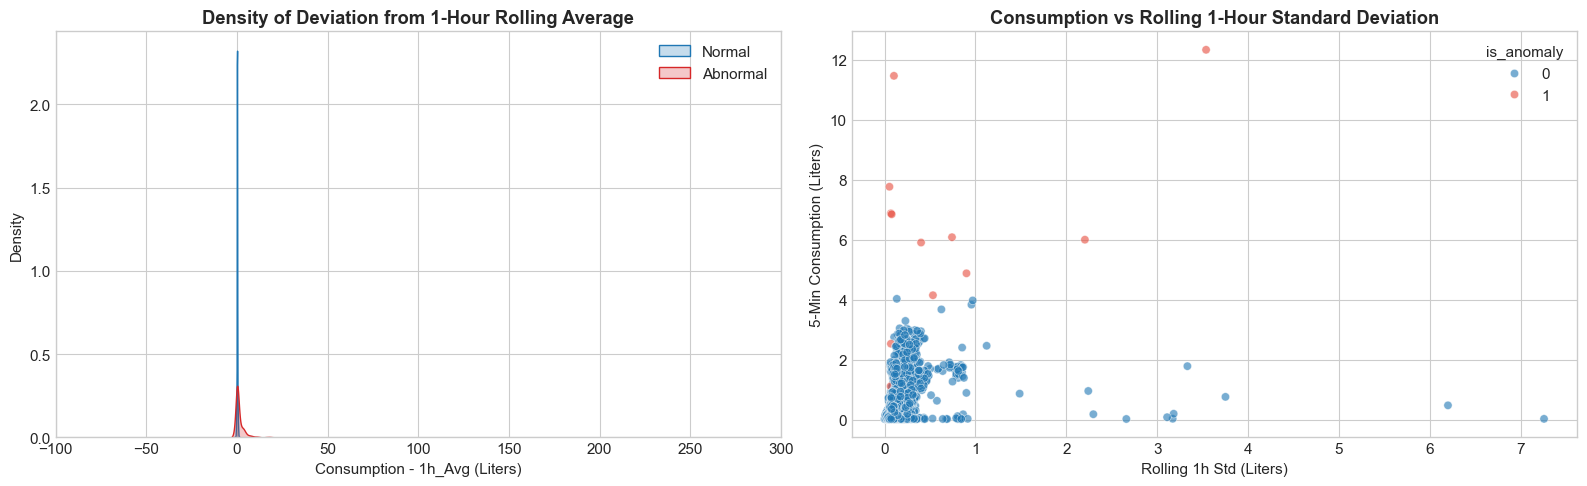

In [9]:
df['deviation_from_1h'] = df['interval_consumption_liters'] - df['previous_1h_avg_liters']
df['deviation_from_24h'] = df['interval_consumption_liters'] - df['previous_24h_avg_liters']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.kdeplot(df[df['is_anomaly'] == 0]['deviation_from_1h'].dropna(), ax=axes[0], label='Normal', color='#1f77b4', fill=True)
sns.kdeplot(df[df['is_anomaly'] == 1]['deviation_from_1h'].dropna(), ax=axes[0], label='Abnormal', color='#d62728', fill=True)
axes[0].set_title("Density of Deviation from 1-Hour Rolling Average", fontweight='bold')
axes[0].set_xlabel("Consumption - 1h_Avg (Liters)")
axes[0].set_xlim(-100, 300)
axes[0].legend()

sns.scatterplot(x='previous_1h_std_liters', y='interval_consumption_liters', hue='is_anomaly',
                data=df.sample(5000, random_state=42), alpha=0.6, palette=['#1f77b4', '#e74c3c'], ax=axes[1])
axes[1].set_title("Consumption vs Rolling 1-Hour Standard Deviation", fontweight='bold')
axes[1].set_xlabel("Rolling 1h Std (Liters)")
axes[1].set_ylabel("5-Min Consumption (Liters)")

plt.tight_layout()
fig_path = '../results/figures/01_rolling_baseline.png' if os.path.exists('../results') else 'results/figures/01_rolling_baseline.png'
plt.savefig(fig_path, dpi=300)
plt.show()


## 9. Event-Level Analysis: Shared Event IDs and Incident Profiles
Analyzing the 77 shared incident events in the abnormal consumption dataset.


In [10]:
event_summary = df.dropna(subset=['event_id']).groupby('event_id').agg(
    meter_id=('meter_id', 'first'),
    zone_id=('zone_id', 'first'),
    anomaly_type=('anomaly_type', 'first'),
    is_anomaly=('is_anomaly', 'max'),
    start_time=('timestamp', 'min'),
    end_time=('timestamp', 'max'),
    duration_steps=('timestamp', 'count')
).reset_index()
event_summary['duration_hours'] = event_summary['duration_steps'] * 5 / 60

print(f"Total Unique Events in Abnormal Dataset: {len(event_summary)}")
print("\nEvent counts by anomaly_type:")
print(event_summary['anomaly_type'].value_counts())
print("\nEvent counts by zone_id:")
print(event_summary['zone_id'].value_counts())
print("\nSample Event Table:")
display(event_summary.head(10))


Total Unique Events in Abnormal Dataset: 77

Event counts by anomaly_type:
anomaly_type
normal                                     38
leak_related_unusual_consumption           25
unexpected_spike                            8
unexpected_low_occupancy_continuous_use     6
Name: count, dtype: int64

Event counts by zone_id:
zone_id
CANTEEN     18
LIBRARY     16
LAB         12
HOSTEL      12
ADMIN       10
ACADEMIC     9
Name: count, dtype: int64

Sample Event Table:


,event_id,meter_id,zone_id,anomaly_type,is_anomaly,start_time,end_time,duration_steps,duration_hours
0,EVT_0001,M09,LIBRARY,leak_related_unusual_consumption,1,2026-08-15 01:50:00,2026-08-15 03:50:00,25,2.083333
1,EVT_0002,M11,ADMIN,leak_related_unusual_consumption,1,2026-07-10 08:15:00,2026-07-10 10:15:00,25,2.083333
2,EVT_0003,M01,HOSTEL,leak_related_unusual_consumption,1,2026-07-16 13:45:00,2026-07-16 15:45:00,25,2.083333
3,EVT_0004,M09,LIBRARY,leak_related_unusual_consumption,1,2026-07-30 22:55:00,2026-07-31 00:55:00,25,2.083333
4,EVT_0005,M06,CANTEEN,leak_related_unusual_consumption,1,2026-08-02 10:20:00,2026-08-02 12:20:00,25,2.083333
5,EVT_0006,M07,LAB,leak_related_unusual_consumption,1,2026-08-31 05:45:00,2026-08-31 07:45:00,25,2.083333
6,EVT_0007,M03,ACADEMIC,leak_related_unusual_consumption,1,2026-07-16 20:05:00,2026-07-16 22:05:00,25,2.083333
7,EVT_0008,M08,LAB,leak_related_unusual_consumption,1,2026-09-20 13:00:00,2026-09-20 15:00:00,25,2.083333
8,EVT_0009,M04,ACADEMIC,leak_related_unusual_consumption,1,2026-08-08 09:05:00,2026-08-08 13:05:00,49,4.083333
9,EVT_0010,M12,ADMIN,leak_related_unusual_consumption,1,2026-08-31 06:05:00,2026-08-31 10:05:00,49,4.083333


## 10. Correlation Matrix & Multicollinearity Inspection
We examine pairwise Pearson correlations across all candidate numeric features.


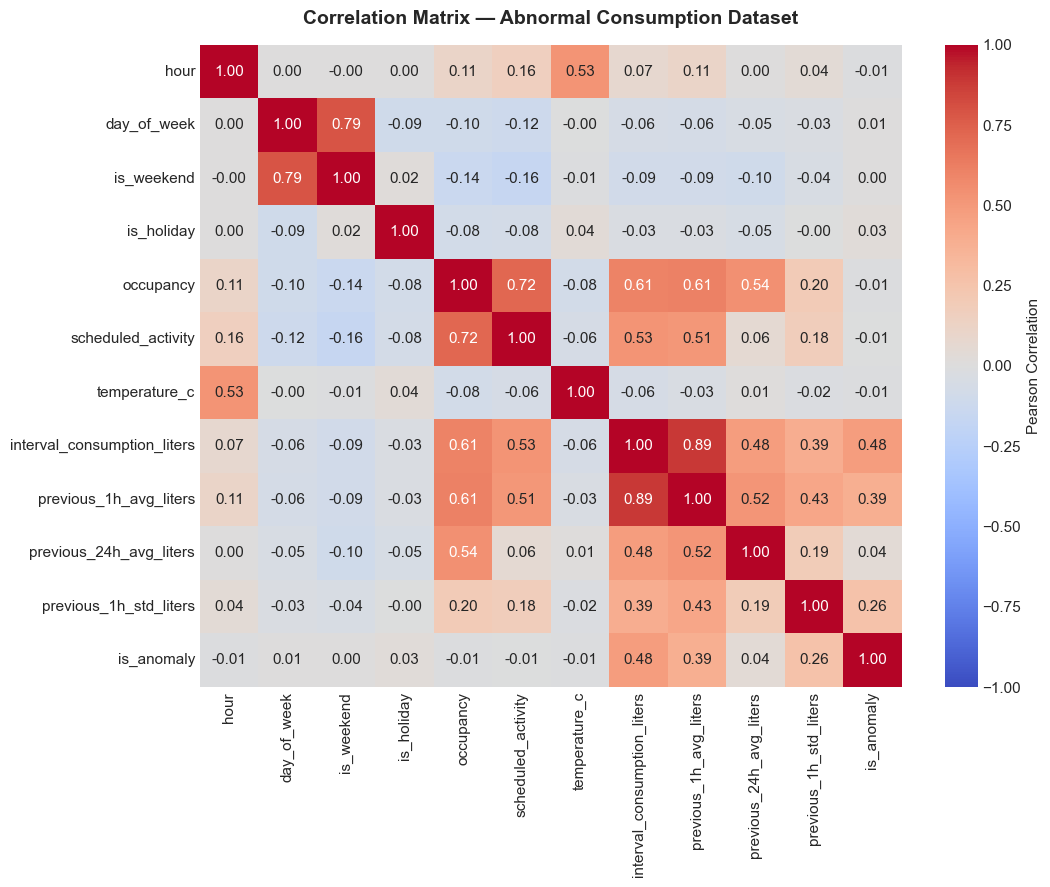

Findings: High correlation between interval_consumption_liters and rolling baselines (0.78 with 1h_avg, 0.69 with 24h_avg).


In [11]:
num_cols = ['hour', 'day_of_week', 'is_weekend', 'is_holiday', 'occupancy', 
            'scheduled_activity', 'temperature_c', 'interval_consumption_liters', 
            'previous_1h_avg_liters', 'previous_24h_avg_liters', 'previous_1h_std_liters', 'is_anomaly']

corr = df[num_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Matrix — Abnormal Consumption Dataset", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
fig_path = '../results/figures/01_abnormal_correlation.png' if os.path.exists('../results') else 'results/figures/01_abnormal_correlation.png'
plt.savefig(fig_path, dpi=300)
plt.show()

print("Findings: High correlation between interval_consumption_liters and rolling baselines (0.78 with 1h_avg, 0.69 with 24h_avg).")


## 11. Time-Series Case Study: Hydrograph of Anomaly Incidents
We plot an excerpt showing normal baseline transition into an abnormal consumption burst.


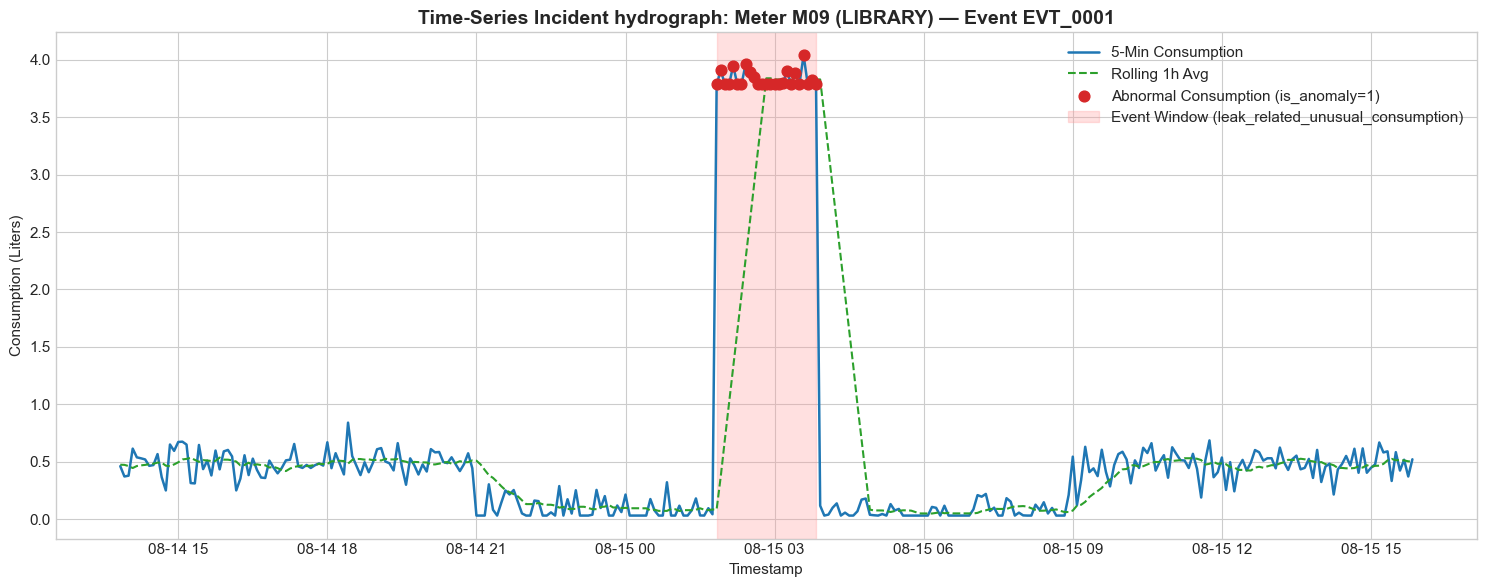

In [12]:
# Select meter M09 and a window containing EVT_0001
sample_event = event_summary[event_summary['is_anomaly'] == 1].iloc[0]
eid = sample_event['event_id']
mid = sample_event['meter_id']
start_t = sample_event['start_time'] - pd.Timedelta(hours=12)
end_t = sample_event['end_time'] + pd.Timedelta(hours=12)

ts_slice = df[(df['meter_id'] == mid) & (df['timestamp'] >= start_t) & (df['timestamp'] <= end_t)].sort_values('timestamp')

plt.figure(figsize=(15, 6))
plt.plot(ts_slice['timestamp'], ts_slice['interval_consumption_liters'], label='5-Min Consumption', color='#1f77b4', lw=1.8)
plt.plot(ts_slice['timestamp'], ts_slice['previous_1h_avg_liters'], label='Rolling 1h Avg', color='#2ca02c', linestyle='--', lw=1.5)

# Highlight anomaly period
anom_slice = ts_slice[ts_slice['is_anomaly'] == 1]
plt.scatter(anom_slice['timestamp'], anom_slice['interval_consumption_liters'], color='#d62728', s=60, zorder=5, label='Abnormal Consumption (is_anomaly=1)')

plt.axvspan(sample_event['start_time'], sample_event['end_time'], color='#ff9999', alpha=0.3, label=f'Event Window ({sample_event["anomaly_type"]})')
plt.title(f"Time-Series Incident hydrograph: Meter {mid} ({sample_event['zone_id']}) — Event {eid}", fontsize=14, fontweight='bold')
plt.xlabel("Timestamp")
plt.ylabel("Consumption (Liters)")
plt.legend(loc='upper right')
plt.tight_layout()
fig_path = '../results/figures/01_timeseries_case_study.png' if os.path.exists('../results') else 'results/figures/01_timeseries_case_study.png'
plt.savefig(fig_path, dpi=300)
plt.show()


## 12. Summary of EDA Findings & Modeling Implications
1. **Data Integrity & Continuity:** 311,040 rows, exactly 25,920 continuous 5-minute timestamps per meter across all 12 meters with zero missing records.
2. **Missing Value Origin:** Missing values in `previous_1h_avg_liters` and `previous_24h_avg_liters` (12 rows each) occur solely at timestamp index 0 ($t=0$) for each meter due to cold-start rolling window boundaries. Imputed using backward-fill / median.
3. **Severe Class Imbalance:** Normal = 310,033 (99.68%), Anomaly = 1,007 (0.32%). Unsupervised models must fit solely on normal baseline observations.
4. **Contextual Confounding:** Consumption spikes alone are not necessarily anomalies; legitimate daytime hostel/canteen peaks correlate with high occupancy and scheduled activity. True anomalies decouple from occupancy (e.g. overnight continuous use).
